## ML Assignment 4 - Gradient Descent Algorithm

Implement the Gradient Descent Algorithm from scratch to find the local/global minimum of an objective function.

Find the local minimum of the function:
$$\mathbf{y = (x + 3)^2}$$
starting from the initial point $\mathbf{x = 2}$.

## 1. Import Libraries & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
import warnings
warnings.filterwarnings('ignore')

# Set plotting aesthetics
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'font.size': 12,
    'axes.labelsize': 12,
    'axes.titlesize': 14,
    'figure.dpi': 110
})

print("All libraries imported successfully!")

All libraries imported successfully!


## Mathematical Formulation

1. Objective Function:
   $$f(x) = (x + 3)^2$$
2. First Derivative (Gradient):
   $$f'(x) = \frac{df}{dx} = 2(x + 3)$$
3. Gradient Descent Update Rule:
   $$x_{t+1} = x_t - \eta \cdot f'(x_t)$$
   where:
   - $x_t$ is the current position at iteration $t$
   - $\eta$ (eta) is the **learning rate** (step size multiplier)
   - $f'(x_t)$ is the **gradient** (slope) at point $x_t$
4. Analytical Solution (Verification):
   $$f'(x) = 0 \implies 2(x + 3) = 0 \implies x^* = -3$$
   $$f(x^*) = (-3 + 3)^2 = 0$$
   Second derivative: $f''(x) = 2 > 0$ (strictly convex, confirming a global minimum at $x = -3$).


## 2. Define Function and its Derivative

In [2]:
def objective_function(x):
    """
    Objective function: y = (x + 3)^2
    """
    return (x + 3) ** 2

def gradient(x):
    """
    First derivative (gradient) of y = (x + 3)^2:
    dy/dx = 2 * (x + 3)
    """
    return 2 * (x + 3)

# Verification at key points
print(f"Function value at initial point x = 2 : f(2) = {objective_function(2)}")
print(f"Gradient at initial point x = 2       : f'(2) = {gradient(2)}")
print(f"Theoretical minimum at x = -3          : f(-3) = {objective_function(-3)}")
print(f"Gradient at theoretical minimum x = -3 : f'(-3) = {gradient(-3)}")

Function value at initial point x = 2 : f(2) = 25
Gradient at initial point x = 2       : f'(2) = 10
Theoretical minimum at x = -3          : f(-3) = 0
Gradient at theoretical minimum x = -3 : f'(-3) = 0



## 3. Implement Gradient Descent Algorithm from Scratch

In [3]:
def gradient_descent(func, grad, start_x, learning_rate=0.1, precision=1e-6, max_iters=1000):
    """
    Performs 1D Gradient Descent optimization.
    
    Parameters:
    -----------
    func          : callable, the objective function f(x)
    grad          : callable, the derivative of the objective function f'(x)
    start_x       : float, initial starting point (x_0)
    learning_rate : float, step size parameter (eta)
    precision     : float, convergence threshold for change in x (|x_new - x_old|)
    max_iters     : int, maximum number of allowed iterations
    
    Returns:
    --------
    optimal_x     : float, estimated point of local minimum
    history       : list of dicts, records iteration trajectory
    """
    current_x = start_x
    history = []
    
    # Record initial state (Iteration 0)
    history.append({
        'iteration': 0,
        'x': current_x,
        'f(x)': func(current_x),
        'gradient': grad(current_x),
        'step_size': 0.0
    })
    
    for i in range(1, max_iters + 1):
        # Compute slope at current position
        grad_val = grad(current_x)
        
        # Update step: move opposite to gradient
        step = learning_rate * grad_val
        new_x = current_x - step
        
        # Record trajectory
        history.append({
            'iteration': i,
            'x': new_x,
            'f(x)': func(new_x),
            'gradient': grad_val,
            'step_size': abs(new_x - current_x)
        })
        
        # Check stopping criteria (convergence threshold)
        if abs(new_x - current_x) < precision:
            print(f"🎯 Converged after {i} iterations (precision threshold {precision} reached)!")
            break
            
        current_x = new_x
    else:
        print(f"⚠️ Reached maximum iterations ({max_iters}) without reaching precision threshold.")
        
    return current_x, history


## 4. Run Gradient Descent on $y = (x + 3)^2$ Starting at $x = 2$

In [4]:
# Hyperparameters
START_X = 2.0
LEARNING_RATE = 0.1
PRECISION = 1e-5
MAX_ITERS = 100

print("=" * 60)
print(f"Running Gradient Descent:")
print(f"  Initial point (x_0) : {START_X}")
print(f"  Learning rate (η)   : {LEARNING_RATE}")
print(f"  Precision threshold : {PRECISION}")
print(f"  Max iterations      : {MAX_ITERS}")
print("=" * 60)

optimal_x, history = gradient_descent(
    func=objective_function,
    grad=gradient,
    start_x=START_X,
    learning_rate=LEARNING_RATE,
    precision=PRECISION,
    max_iters=MAX_ITERS
)

min_y = objective_function(optimal_x)

print("\n" + "=" * 60)
print("                    OPTIMIZATION RESULTS")
print("=" * 60)
print(f"  Computed Local Minimum at x  : {optimal_x:.6f}")
print(f"  Function value f(x) at min   : {min_y:.8f}")
print(f"  Gradient at computed minimum : {gradient(optimal_x):.8f}")
print(f"  Theoretical Minimum          : x = -3.000000, f(x) = 0.000000")
print(f"  Absolute Error (|x - x*|)    : {abs(optimal_x - (-3)):.8f}")
print(f"  Total Iterations Taken       : {len(history) - 1}")
print("=" * 60)

Running Gradient Descent:
  Initial point (x_0) : 2.0
  Learning rate (η)   : 0.1
  Precision threshold : 1e-05
  Max iterations      : 100
🎯 Converged after 53 iterations (precision threshold 1e-05 reached)!

                    OPTIMIZATION RESULTS
  Computed Local Minimum at x  : -2.999954
  Function value f(x) at min   : 0.00000000
  Gradient at computed minimum : 0.00009134
  Theoretical Minimum          : x = -3.000000, f(x) = 0.000000
  Absolute Error (|x - x*|)    : 0.00004567
  Total Iterations Taken       : 53


### 4.1 Iteration History Table

In [5]:
# Convert history to DataFrame
df_history = pd.DataFrame(history)

print("First 10 Iterations:")
print(df_history.head(10).to_string(index=False))

print("\nLast 5 Iterations:")
print(df_history.tail(5).to_string(index=False))

First 10 Iterations:
 iteration         x      f(x)  gradient  step_size
         0  2.000000 25.000000 10.000000   0.000000
         1  1.000000 16.000000 10.000000   1.000000
         2  0.200000 10.240000  8.000000   0.800000
         3 -0.440000  6.553600  6.400000   0.640000
         4 -0.952000  4.194304  5.120000   0.512000
         5 -1.361600  2.684355  4.096000   0.409600
         6 -1.689280  1.717987  3.276800   0.327680
         7 -1.951424  1.099512  2.621440   0.262144
         8 -2.161139  0.703687  2.097152   0.209715
         9 -2.328911  0.450360  1.677722   0.167772

Last 5 Iterations:
 iteration         x         f(x)  gradient  step_size
        49 -2.999911 7.957172e-09  0.000223   0.000022
        50 -2.999929 5.092590e-09  0.000178   0.000018
        51 -2.999943 3.259258e-09  0.000143   0.000014
        52 -2.999954 2.085925e-09  0.000114   0.000011
        53 -2.999963 1.334992e-09  0.000091   0.000009



## 5. Visualizations

### 5.1 Trajectory on the Objective Curve $y = (x + 3)^2$

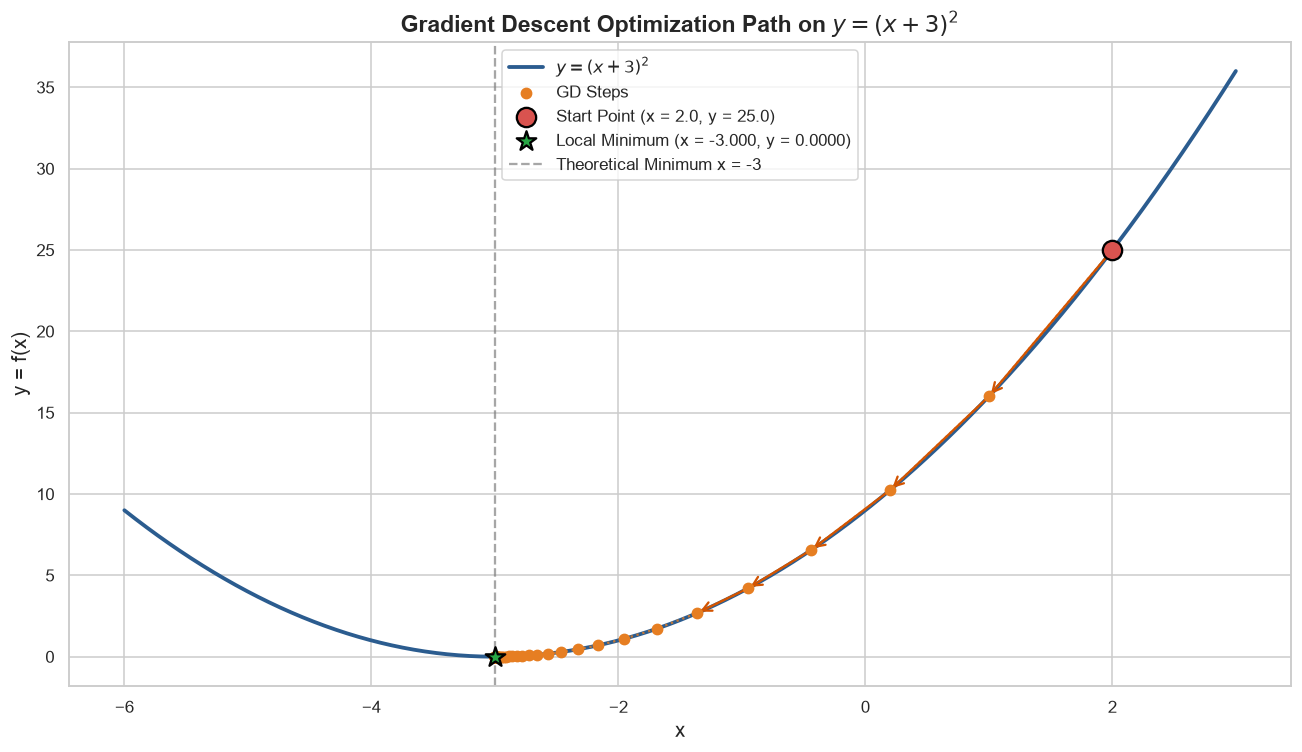

In [6]:
# Curve values
x_curve = np.linspace(-6, 3, 500)
y_curve = objective_function(x_curve)

# Extracted points from trajectory
x_hist = df_history['x'].values
y_hist = df_history['f(x)'].values

plt.figure(figsize=(12, 7))

# Plot the function curve
plt.plot(x_curve, y_curve, color='#2b5c8f', lw=2.5, label=r'$y = (x + 3)^2$')

# Plot gradient descent steps
plt.scatter(x_hist, y_hist, color='#e67e22', s=45, zorder=4, label='GD Steps')
plt.plot(x_hist, y_hist, color='#e67e22', linestyle=':', lw=1.5, alpha=0.8)

# Highlight start and minimum points
plt.scatter([x_hist[0]], [y_hist[0]], color='#d9534f', s=160, zorder=5,
            edgecolor='black', lw=1.5, label=f'Start Point (x = {x_hist[0]:.1f}, y = {y_hist[0]:.1f})')
plt.scatter([optimal_x], [min_y], color='#28a745', s=180, marker='*', zorder=5,
            edgecolor='black', lw=1.5, label=f'Local Minimum (x = {optimal_x:.3f}, y = {min_y:.4f})')

# Annotate key arrows
for i in range(min(5, len(x_hist) - 1)):
    plt.annotate('', xy=(x_hist[i+1], y_hist[i+1]), xytext=(x_hist[i], y_hist[i]),
                 arrowprops=dict(arrowstyle='->', color='#d35400', lw=1.5, mutation_scale=15))

plt.title(r'Gradient Descent Optimization Path on $y = (x + 3)^2$', fontsize=15, fontweight='bold')
plt.xlabel('x', fontsize=13)
plt.ylabel('y = f(x)', fontsize=13)
plt.axvline(x=-3, color='gray', linestyle='--', alpha=0.7, label='Theoretical Minimum x = -3')
plt.legend(fontsize=11, loc='upper center')
plt.tight_layout()
plt.show()

### 5.2 Convergence Analysis: Loss & Parameter Decay per Iteration

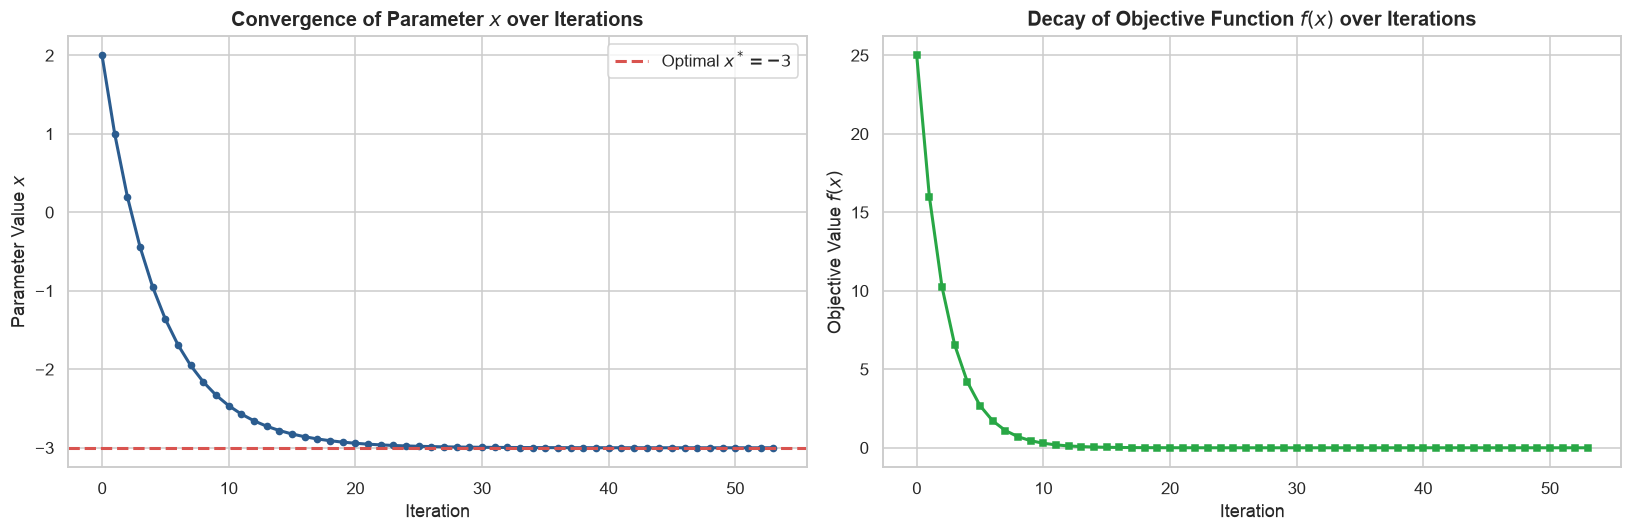

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Value of x vs Iteration
axes[0].plot(df_history['iteration'], df_history['x'], 'o-', color='#2b5c8f', lw=2, markersize=4)
axes[0].axhline(y=-3.0, color='#d9534f', linestyle='--', lw=2, label='Optimal $x^* = -3$')
axes[0].set_title('Convergence of Parameter $x$ over Iterations', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Parameter Value $x$')
axes[0].legend()

# 2. Objective Value f(x) vs Iteration
axes[1].plot(df_history['iteration'], df_history['f(x)'], 's-', color='#28a745', lw=2, markersize=4)
axes[1].set_title('Decay of Objective Function $f(x)$ over Iterations', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('Objective Value $f(x)$')

plt.tight_layout()
plt.show()


## 6. Sensitivity Analysis: Effect of Learning Rate ($\eta$)

The learning rate $\eta$ is the most critical hyperparameter in Gradient Descent:
- **Too Small (e.g., $\eta = 0.01$):** Converges reliably but requires an excessive number of iterations (slow).
- **Moderate / Optimal (e.g., $\eta = 0.1$ or $0.2$):** Fast, smooth, and stable convergence.
- **Large (e.g., $\eta = 0.8$):** Oscillates across the valley but eventually settles.
- **Too Large / Divergent (e.g., $\eta \ge 1.0$):** Overshoots the minimum and diverges ($|x| \to \infty$).

⚠️ Reached maximum iterations (25) without reaching precision threshold.
⚠️ Reached maximum iterations (25) without reaching precision threshold.
🎯 Converged after 25 iterations (precision threshold 1e-05 reached)!
⚠️ Reached maximum iterations (25) without reaching precision threshold.
⚠️ Reached maximum iterations (25) without reaching precision threshold.


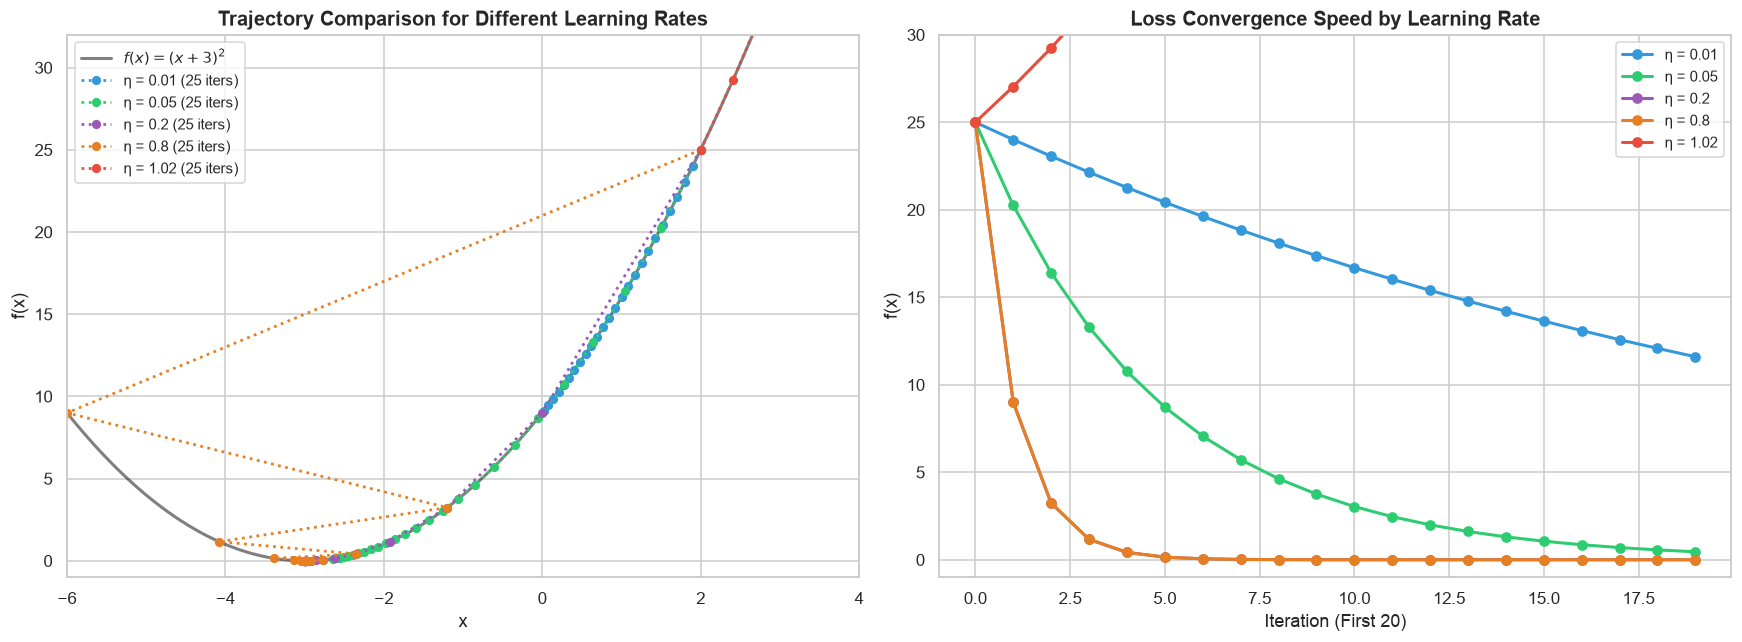

In [8]:
learning_rates = [0.01, 0.05, 0.2, 0.8, 1.02]
colors = ['#3498db', '#2ecc71', '#9b59b6', '#e67e22', '#e74c3c']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: Trajectory on function curve for different learning rates
axes[0].plot(x_curve, y_curve, color='black', lw=2, alpha=0.5, label=r'$f(x)=(x+3)^2$')

for lr, col in zip(learning_rates, colors):
    opt_x, hist = gradient_descent(
        objective_function, gradient, start_x=START_X,
        learning_rate=lr, precision=1e-5, max_iters=25
    )
    xs = [h['x'] for h in hist]
    ys = [h['f(x)'] for h in hist]
    iters = len(hist) - 1
    
    # Plot steps on curve (clamp to visible range)
    valid_pts = [(x, y) for x, y in zip(xs, ys) if -6 <= x <= 4 and y <= 35]
    if valid_pts:
        vx, vy = zip(*valid_pts)
        axes[0].plot(vx, vy, 'o:', color=col, lw=1.8, markersize=5,
                     label=f'η = {lr} ({iters} iters)')
    
    # Right: Loss vs Iteration
    axes[1].plot(range(min(20, len(ys))), ys[:20], 'o-', color=col, lw=2,
                 label=f'η = {lr}')

axes[0].set_title('Trajectory Comparison for Different Learning Rates', fontsize=13, fontweight='bold')
axes[0].set_xlabel('x')
axes[0].set_ylabel('f(x)')
axes[0].set_ylim(-1, 32)
axes[0].set_xlim(-6, 4)
axes[0].legend(fontsize=10)

axes[1].set_title('Loss Convergence Speed by Learning Rate', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Iteration (First 20)')
axes[1].set_ylabel('f(x)')
axes[1].set_ylim(-1, 30)
axes[1].legend(fontsize=10)

plt.tight_layout()
plt.show()


## 7. Extension: Gradient Descent on a Non-Convex Function (Local vs Global Minima)

To understand the practical challenge in deep learning where loss surfaces are non-convex, consider:
$$f(x) = x^4 - 3x^3 + 2$$

🎯 Converged after 8 iterations (precision threshold 1e-06 reached)!
🎯 Converged after 11 iterations (precision threshold 1e-06 reached)!


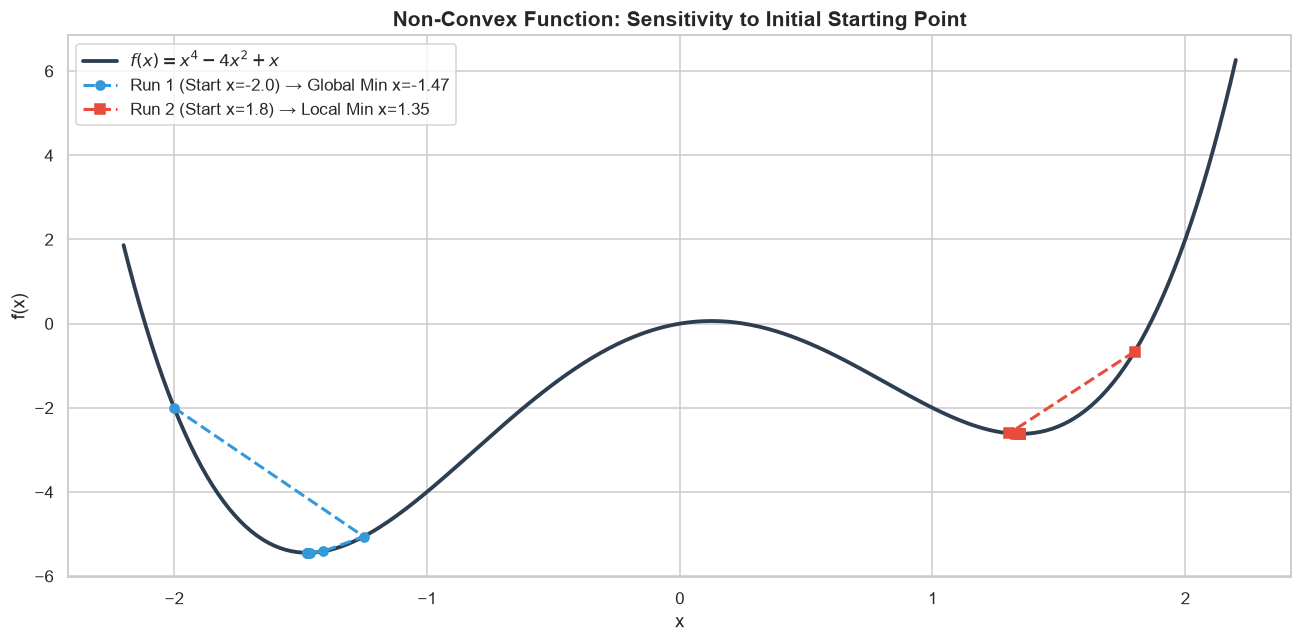

💡 Insight: In non-convex optimization, the initial starting point determines whether
   the algorithm discovers the global minimum or becomes trapped in a local minimum.


In [9]:
# Non-convex function
def non_convex_func(x):
    return x**4 - 4*x**2 + x

def non_convex_grad(x):
    return 4*x**3 - 8*x + 1

x_nc = np.linspace(-2.2, 2.2, 400)
y_nc = non_convex_func(x_nc)

# Run from two different starting points
opt_x1, hist1 = gradient_descent(non_convex_func, non_convex_grad, start_x=-2.0, learning_rate=0.05, max_iters=50)
opt_x2, hist2 = gradient_descent(non_convex_func, non_convex_grad, start_x=1.8,  learning_rate=0.05, max_iters=50)

plt.figure(figsize=(12, 6))
plt.plot(x_nc, y_nc, color='#2c3e50', lw=2.5, label=r'$f(x) = x^4 - 4x^2 + x$')

# Path 1
x1_pts = [h['x'] for h in hist1]
y1_pts = [h['f(x)'] for h in hist1]
plt.plot(x1_pts, y1_pts, 'o--', color='#3498db', lw=2, label=f'Run 1 (Start x=-2.0) → Global Min x={opt_x1:.2f}')

# Path 2
x2_pts = [h['x'] for h in hist2]
y2_pts = [h['f(x)'] for h in hist2]
plt.plot(x2_pts, y2_pts, 's--', color='#e74c3c', lw=2, label=f'Run 2 (Start x=1.8) → Local Min x={opt_x2:.2f}')

plt.title('Non-Convex Function: Sensitivity to Initial Starting Point', fontsize=14, fontweight='bold')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

print("💡 Insight: In non-convex optimization, the initial starting point determines whether")
print("   the algorithm discovers the global minimum or becomes trapped in a local minimum.")